# Homework assignment #3

## 1. Apply a Logistic Regression model

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

np.random.seed(42)
df = pd.read_csv('bioresponse.csv')

X = df.iloc[:, 1:].to_numpy(dtype=float)
Y = df.iloc[:, 0].to_numpy(dtype=int)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42)

train_set_x = X_train.T
train_set_y = Y_train.reshape(1, -1)
test_set_x = X_test.T
test_set_y = Y_test.reshape(1, -1)

print('Shape:', df.shape)
print('Train:', train_set_x.shape, 'Test:', test_set_x.shape)

Shape: (3751, 1777)
Train: (1776, 2813) Test: (1776, 938)


In [35]:
def sigmoid(z):
    return 1./(1.+np.exp(-z))

def initialize_with_zeros(dim):
    w = np.zeros((dim, 1))
    b = 0.
    return w, b

def propagate(w, b, X, Y):
    m = X.shape[1]
    A = sigmoid(np.dot(w.T,X)+b )
    A = np.clip(A, 1e-12, 1 - 1e-12)
    cost = -(1./m)*np.sum(Y*np.log(A)+(1-Y)*np.log(1-A),axis=1)
    dw = (1./m)*np.dot(X,(A-Y).T)
    db = (1./m)*np.sum(A-Y,axis=1)
    return {"dw": dw, "db": db}, cost

def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost = False):
    costs = []
    for i in range(num_iterations):
        grads, cost = propagate(w,b,X,Y)
        dw = grads["dw"]
        db = grads["db"]

        w -=learning_rate * dw
        b -=learning_rate * db

        if i % 100 == 0:
            costs.append(cost)

        if print_cost and i % 100 == 0:
            print (f"Cost after iteration {i}: {round(cost[0], 7)}")

    params = {"w": w, "b": b}
    grads = {"dw": dw, "db": db}

    return params, grads, costs

def predict(w, b, X, threshold):
    m = X.shape[1]
    Y_prediction = np.zeros((1,m))
    w = w.reshape(X.shape[0], 1)
    A = sigmoid(np.dot(w.T,X)+b)
    for i in range(A.shape[1]):
        if (A[0,i]<=threshold):
            Y_prediction[0][i]=0
        else:
            Y_prediction[0][i]=1

    return Y_prediction

def model(X_train, Y_train, X_test, Y_test, num_iterations = 2000, learning_rate = 0.5, print_cost = False):
    w, b = initialize_with_zeros(X_train.shape[0])
    parameters, grads, costs = optimize(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost)

    w = parameters["w"]
    b = parameters["b"]

    Y_prediction_test = predict(w, b, X_test, 0.5)
    Y_prediction_train = predict(w, b, X_train, 0.5)

    print(f"train accuracy: {100 - np.mean(np.abs(Y_prediction_train - Y_train) * 100)}")
    print(f"test accuracy: {100 - np.mean(np.abs(Y_prediction_test - Y_test) * 100)}")

    d = {"costs": costs,
         "Y_prediction_test": Y_prediction_test,
         "Y_prediction_train" : Y_prediction_train,
         "w" : w,
         "b" : b,
         "learning_rate" : learning_rate,
         "num_iterations": num_iterations}

    return d


d_gd = model(train_set_x, train_set_y, test_set_x, test_set_y, num_iterations=300, learning_rate=0.01, print_cost=False)
print('GD test accuracy:', 100 - np.mean(np.abs(d_gd['Y_prediction_test'] - test_set_y) * 100))

train accuracy: 73.19587628865979
test accuracy: 73.02771855010661
GD test accuracy: 73.02771855010661


## 2. Modify optimize() function to implement the stochastic gradient descent (SGD) method

In [36]:
def optimize_sgd(w, b, X, Y, num_iterations, learning_rate, print_cost = False):
    costs = []
    m = X.shape[1]
    rng = np.random.default_rng(42)
    for i in range(num_iterations):
        for j in rng.permutation(m):
            grads, cost = propagate(w, b, X[:, j:j+1], Y[:, j:j+1])
            dw = grads['dw']
            db = grads['db']
            w -= learning_rate * dw
            b -= learning_rate * db
        grads, cost = propagate(w, b, X, Y)
        costs.append(float(cost[0]))
        if print_cost and i % 10 == 0:
            print(f'Cost after epoch {i}: {cost[0]:.7f}')
    params = {'w': w, 'b': b}
    return params, grads, costs

## 3. Implement the Adam optimization method

In [37]:
def optimize_adam(w, b, X, Y, num_iterations, learning_rate, print_cost = False):
    costs = []
    beta1, beta2, eps = 0.9, 0.999, 1e-8
    mw, vw = np.zeros_like(w), np.zeros_like(w)
    mb, vb = np.zeros_like(b), np.zeros_like(b)
    for i in range(num_iterations):
        grads, cost = propagate(w, b, X, Y)
        dw, db = grads['dw'], grads['db']
        mw = beta1 * mw + (1 - beta1) * dw
        vw = beta2 * vw + (1 - beta2) * dw**2
        mb = beta1 * mb + (1 - beta1) * db
        vb = beta2 * vb + (1 - beta2) * db**2
        t = i + 1
        w -= learning_rate * (mw / (1 - beta1**t)) / (np.sqrt(vw / (1 - beta2**t)) + eps)
        b -= learning_rate * (mb / (1 - beta1**t)) / (np.sqrt(vb / (1 - beta2**t)) + eps)
        if i % 100 == 0:
            costs.append(float(cost[0]))
        if print_cost and i % 100 == 0:
            print(f'Cost after iteration {i}: {cost[0]:.7f}')
    return {'w': w, 'b': b}, grads, costs

## 4. Plot learning curves

      Train accuracy, %  Test accuracy, %
GD                73.20             73.03
SGD               75.40             73.45
Adam              82.79             76.01


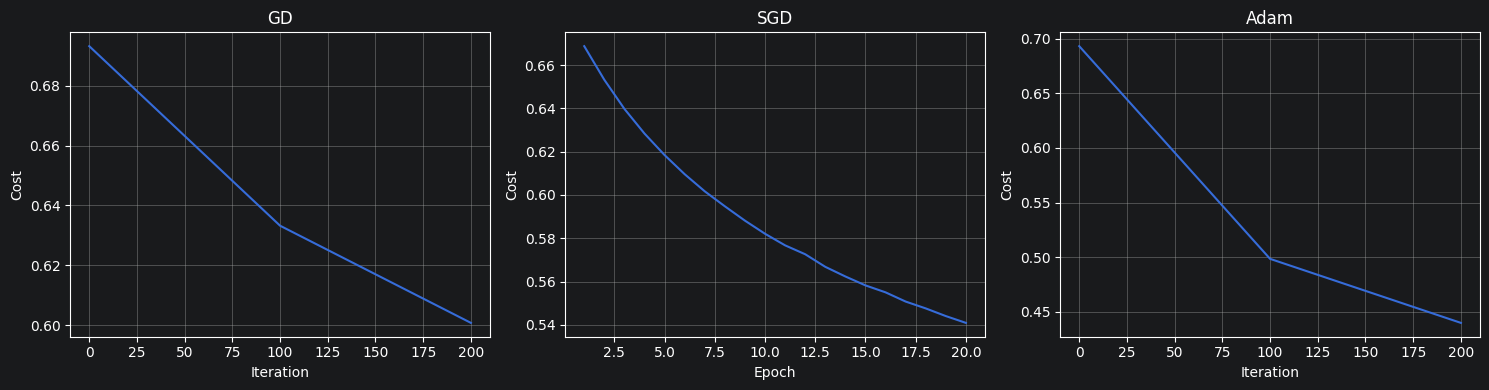

In [38]:
def run_optimizer(method, iterations, learning_rate):
    w, b = initialize_with_zeros(train_set_x.shape[0])
    if method == 'GD':
        params, grads, costs = optimize(w, b, train_set_x, train_set_y, iterations, learning_rate)
        x_axis = np.arange(len(costs)) * 100
    elif method == 'SGD':
        params, grads, costs = optimize_sgd(w, b, train_set_x, train_set_y, iterations, learning_rate)
        x_axis = np.arange(1, len(costs) + 1)
    else:
        params, grads, costs = optimize_adam(w, b, train_set_x, train_set_y, iterations, learning_rate)
        x_axis = np.arange(len(costs)) * 100
    pred_train = predict(params['w'], params['b'], train_set_x, 0.5)
    pred_test = predict(params['w'], params['b'], test_set_x, 0.5)
    return {'costs': costs, 'x_axis': x_axis,
            'train_accuracy': 100 - np.mean(np.abs(pred_train - train_set_y) * 100),
            'test_accuracy': 100 - np.mean(np.abs(pred_test - test_set_y) * 100)}

experiments = {
    'GD': run_optimizer('GD', 300, 0.01),
    'SGD': run_optimizer('SGD', 20, 0.0001),
    'Adam': run_optimizer('Adam', 300, 0.001),
}
comparison = pd.DataFrame({name: {'Train accuracy, %': r['train_accuracy'],
                                   'Test accuracy, %': r['test_accuracy']}
                           for name, r in experiments.items()}).T
print(comparison.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, r) in zip(axes, experiments.items()):
    ax.plot(r['x_axis'], r['costs'])
    ax.set_title(name)
    ax.set_xlabel('Epoch' if name == 'SGD' else 'Iteration')
    ax.set_ylabel('Cost')
    ax.grid()
plt.tight_layout()
plt.show()

## 5. Train the models with different values of the learning rate

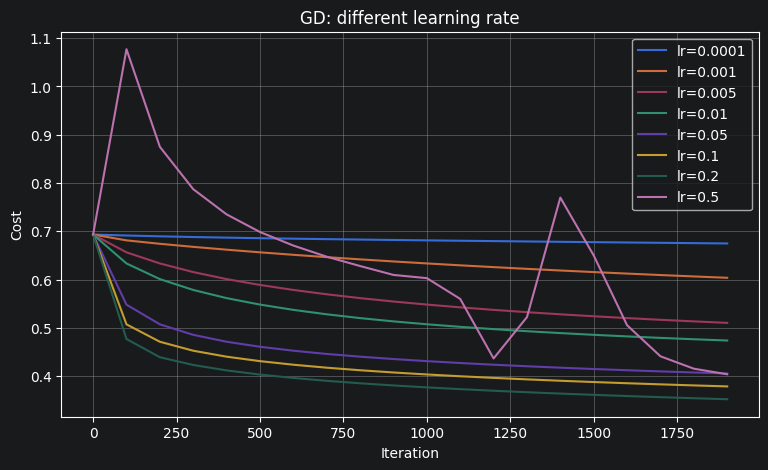

  Learning rate  Test accuracy, %
0        0.0001             60.66
1         0.001             72.71
2         0.005             74.73
3          0.01             75.59
4          0.05             76.97
5           0.1             76.44
6           0.2             75.37
7           0.5             72.92
How does it affect the accuracy of the model? Answer: Test accuracy is growing with increasing learning rate but then drops after some point. The best test accuracy was 76.97% with learning rate 0.05


In [39]:
learning_rates = [0.0001, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.5]
lr_results = {}
plt.figure(figsize=(9, 5))
for lr in learning_rates:
    r = run_optimizer('GD', 2000, lr)
    lr_results[lr] = r
    plt.plot(r['x_axis'], r['costs'], label=f'lr={lr}')
plt.xlabel('Iteration')
plt.ylabel('Cost')
plt.title('GD: different learning rate')
plt.grid()
plt.legend()
plt.show()
res = pd.DataFrame([{'Learning rate': f'{lr:g}', 'Test accuracy, %': round(r['test_accuracy'], 2)} for lr, r in lr_results.items()])
print(res)
best_lr_by_accuracy = res.loc[res['Test accuracy, %'].idxmax()]
best_lr = best_lr_by_accuracy['Learning rate']
best_acc = best_lr_by_accuracy['Test accuracy, %']
print(f'How does it affect the accuracy of the model? Answer: Test accuracy is growing with increasing learning rate but then drops after some point. The best test accuracy was {best_acc}% with learning rate {best_lr}')


## 6. Conclusions

1. All three algorithms trained the model. With the given parameters GD shows test accuracy as 73.03%, SGD as 73.45% and Adam as 76.01%. Adam is the best in this case.

2. Investigating learning rate for GD shows that training with small step is very slow. With increasing learning rate test accuracy grows, but drops at some point.

3. The model's effectiveness depends not only on the optimization algorithm but also in its parameters (like iterations and learning rate)
